# Regime-Dependent Risk & Performance Attribution

**Research question:** Do full-sample risk metrics misrepresent asset risk profiles across market regimes?

**Thesis:** Yes. CAPM beta, volatility, VaR, and Sharpe ratio all vary materially across regimes. Full-sample averages are statistical artefacts that mask the true risk profile of every asset examined.

**Assets:** NVDA, JPM, PG (equity); SPY (benchmark) | **Period:** 2019–2024  
**Regime classifier:** SPY 30-day rolling volatility split at in-sample median → Low-Vol / High-Vol  
**Pipeline:** Regime detection → per-regime CAPM (HC3) → risk metrics → GARCH VaR → stress testing

---
## 1. Imports

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import seaborn as sns
import yfinance as yf
import statsmodels.api as sm
from scipy import stats
from arch import arch_model

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

COLORS = {'Low-Vol': '#2ecc71', 'High-Vol': '#e74c3c', 'Full Sample': '#3498db'}
TICKER_COLORS = {'NVDA': '#9b59b6', 'JPM': '#e67e22', 'PG': '#1abc9c', 'SPY': '#2c3e50'}
TICKERS = ['NVDA', 'JPM', 'PG', 'SPY']

# Risk-free rate: annualised 3-month T-bill average 2019–2023.
# Using 0% overstates Sharpe materially for 2022–23 when Fed Funds hit 4–5%.
RF_ANNUAL = 0.025
RF_DAILY  = RF_ANNUAL / 252

---
## 2. Data Loading

In [2]:
# auto_adjust=True ensures 'Close' is split/dividend-adjusted.
# Without it, NVDA's 4-for-1 split (Jul 2021) creates artificial return spikes.
raw = yf.download(
    TICKERS, start='2019-01-01', end='2024-01-01',
    group_by='ticker', auto_adjust=True, progress=False
)

prices = pd.DataFrame({t: raw[(t, 'Close')] for t in TICKERS}).dropna(how='any')
print(f'Loaded {len(prices)} trading days: {prices.index[0].date()} → {prices.index[-1].date()}')
prices.describe().round(2)

Loaded 1258 trading days: 2019-01-02 → 2023-12-29


,NVDA,JPM,PG,SPY
count,1258.00,1258.00,1258.00,1258.00
mean,17.71,115.47,120.19,351.56
std,12.46,22.45,18.28,65.43
min,3.17,67.10,75.38,204.94
25%,6.80,94.53,105.25,286.00
50%,14.55,116.73,122.18,368.56
75%,23.05,135.21,135.90,408.04
max,50.37,162.15,148.40,463.92


---
## 3. Data Preprocessing — Log Returns & Distributional Diagnostics

In [3]:
# Log returns: time-additive, symmetric, well-defined for compounding
rets = np.log(prices / prices.shift(1)).dropna()

# Distributional diagnostics: confirm fat tails before any risk modelling
diag = {}
print(f"{'Ticker':<6} {'Excess Kurt':>12} {'Skew':>8} {'JB p-val':>12} {'ADF p-val':>12}")
print('-' * 52)
for t in TICKERS:
    r = rets[t]
    kurt, skew   = stats.kurtosis(r), stats.skew(r)
    _, jb_p      = stats.jarque_bera(r)
    from statsmodels.tsa.stattools import adfuller
    adf_p = adfuller(r, autolag='AIC')[1]
    diag[t] = dict(kurt=kurt, skew=skew, jb_p=jb_p, adf_p=adf_p)
    print(f'{t:<6} {kurt:>12.3f} {skew:>8.3f} {jb_p:>12.2e} {adf_p:>12.2e}')

print('\nAll JB p-values ≈ 0: normality rejected. All ADF p-values ≈ 0: returns stationary.')
print('Fat tails confirmed → Normal VaR will systematically underestimate tail risk.')

Ticker  Excess Kurt     Skew     JB p-val    ADF p-val
----------------------------------------------------
NVDA          4.045    0.051    6.92e-187     9.71e-20
JPM          12.887   -0.052     0.00e+00     1.09e-17
PG           11.281   -0.102     0.00e+00     3.18e-20
SPY          12.363   -0.820     0.00e+00     9.05e-19

All JB p-values ≈ 0: normality rejected. All ADF p-values ≈ 0: returns stationary.
Fat tails confirmed → Normal VaR will systematically underestimate tail risk.


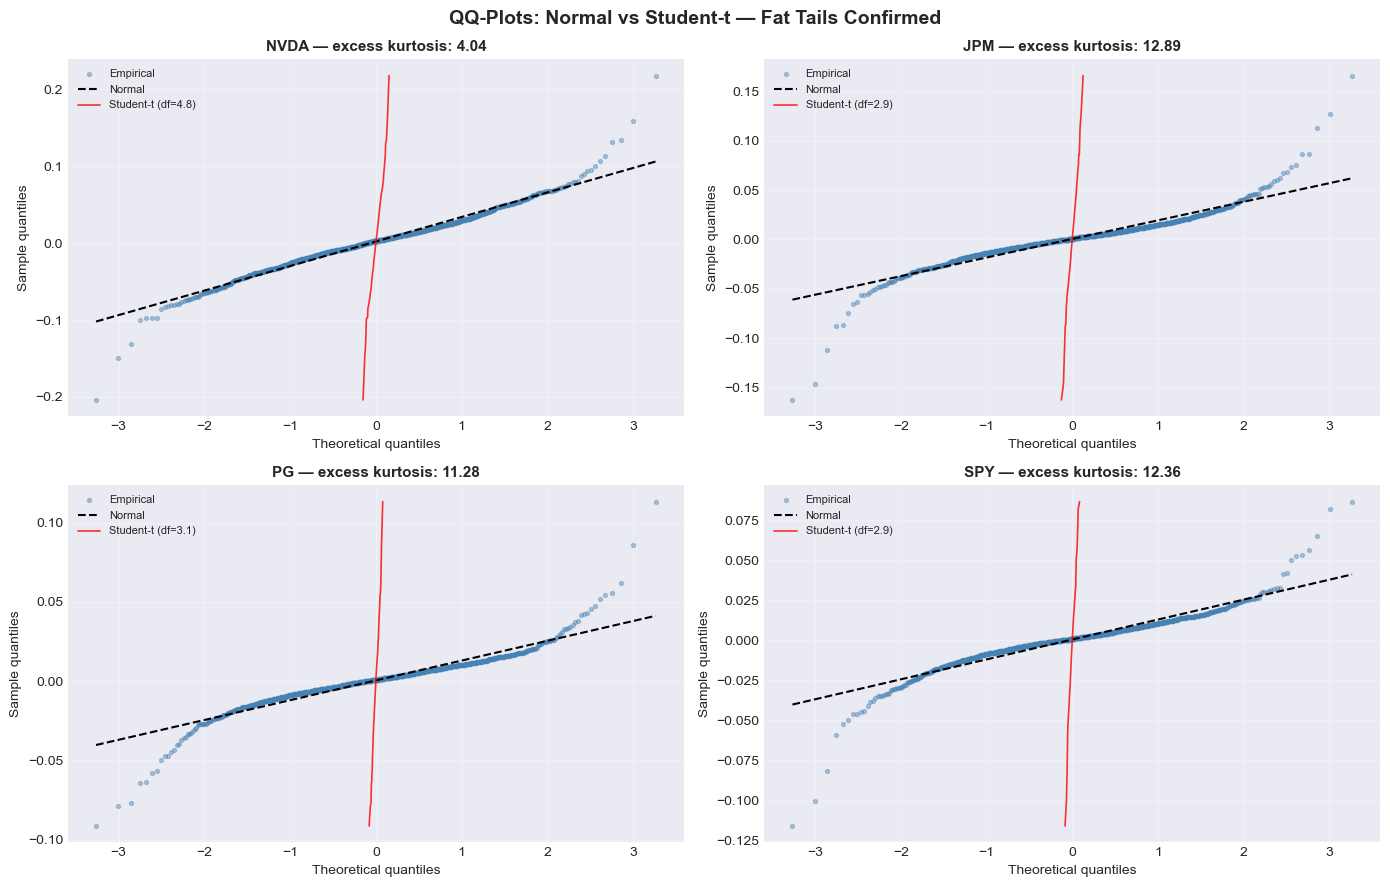

In [4]:
# QQ-plots confirm fat tails: Student-t fits the empirical distribution far better than Normal.
# Lower fitted df → heavier tails.
from scipy.stats import t as t_dist

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle('QQ-Plots: Normal vs Student-t — Fat Tails Confirmed', fontsize=14, fontweight='bold')

for ax, t in zip(axes.flatten(), TICKERS):
    r = rets[t].values
    (osm, osr), (slope, intercept, _) = stats.probplot(r, dist='norm')
    ax.scatter(osm, osr, s=8, alpha=0.4, color='steelblue', label='Empirical')
    ax.plot(osm, slope * np.array(osm) + intercept, 'k--', lw=1.5, label='Normal')

    df_fit, loc_fit, scale_fit = t_dist.fit(r)
    t_q = np.sort(t_dist.ppf(np.linspace(0.001, 0.999, len(r)), df=df_fit, loc=loc_fit, scale=scale_fit))
    ax.plot(t_q, np.sort(r), 'r-', lw=1.2, alpha=0.8, label=f'Student-t (df={df_fit:.1f})')

    ax.set_title(f'{t} — excess kurtosis: {diag[t]["kurt"]:.2f}', fontsize=11, fontweight='bold')
    ax.set_xlabel('Theoretical quantiles'); ax.set_ylabel('Sample quantiles')
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 4. Feature Engineering — Regime Classification

In [5]:
# Regime classifier: SPY 30-day rolling vol vs. full-sample median.
# Median split → balanced classes (~50/50), ensuring reliable per-regime estimation.
# Look-ahead note: full-sample median is acceptable for retrospective attribution;
# a live system would use an expanding-window median.

spy_rvol = rets['SPY'].rolling(30).std()
threshold = spy_rvol.median()

regime = pd.Series(np.where(spy_rvol > threshold, 'High-Vol', 'Low-Vol'),
                   index=spy_rvol.index).reindex(rets.index)

# Restrict to days with a valid regime label (first 30 days have NaN rolling vol)
valid_idx = regime.dropna().index
rets_a    = rets.loc[valid_idx]
regime_a  = regime.loc[valid_idx]

vc = regime_a.value_counts()
for r, n in vc.items():
    print(f'  {r:<10}: {n:>4} days ({100*n/vc.sum():.1f}%)')
print(f'  Threshold  : {threshold:.5f} (daily σ)')

  Low-Vol   :  643 days (51.2%)
  High-Vol  :  614 days (48.8%)
  Threshold  : 0.00927 (daily σ)


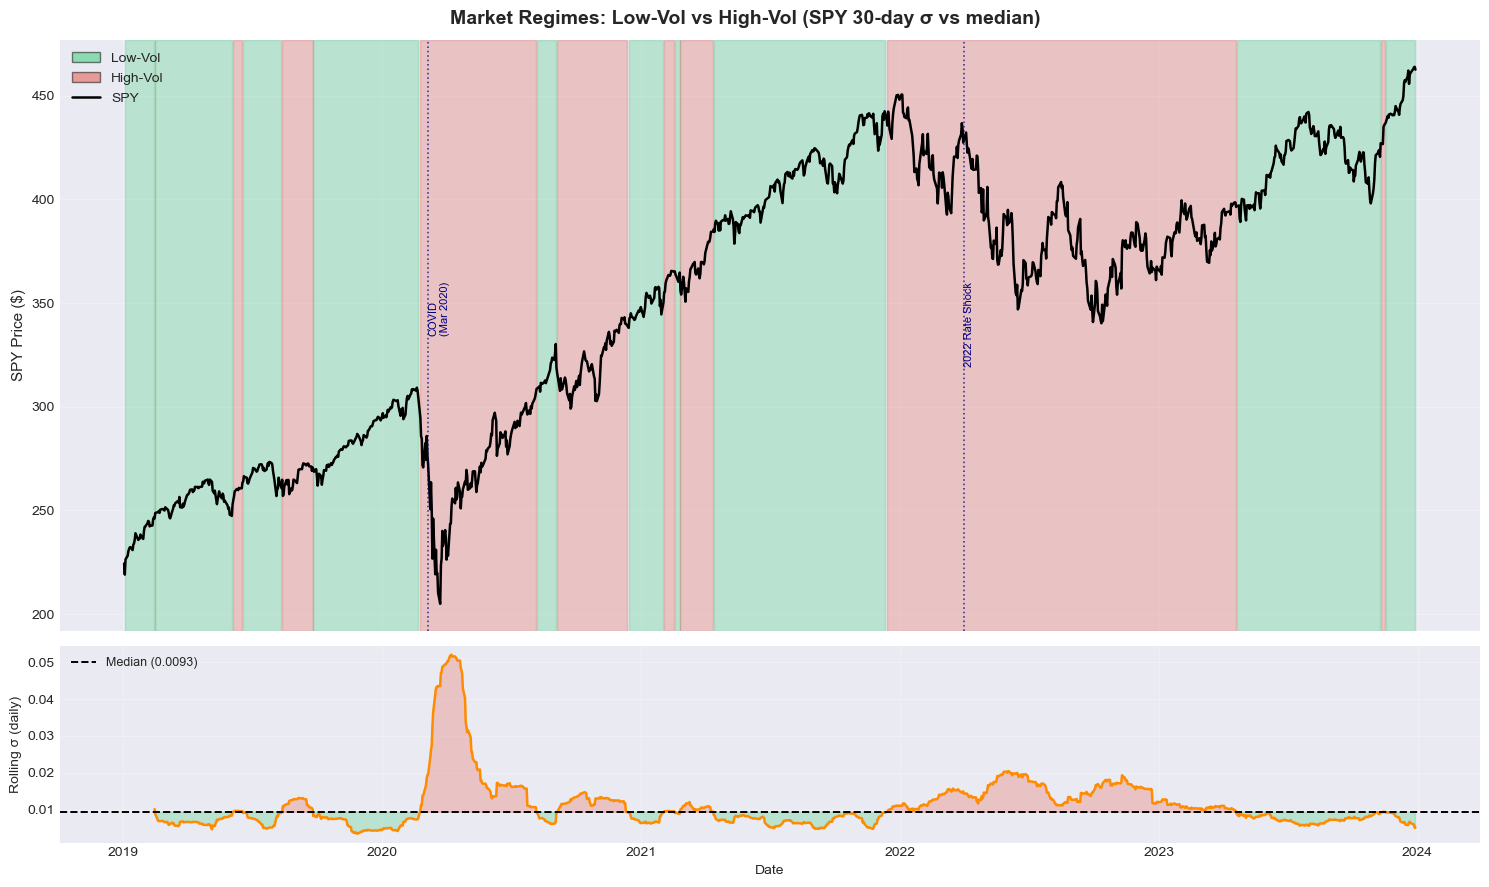

In [6]:
# Regime visualisation: SPY price with shaded regimes + rolling vol panel
from itertools import groupby

def shade_regimes(ax, regime_series):
    """Shade contiguous regime blocks — one axvspan per run (not per day)."""
    dates = regime_series.index
    for val, grp in groupby(enumerate(regime_series), key=lambda x: x[1]):
        if pd.isna(val): continue
        idxs = list(grp)
        ax.axvspan(dates[idxs[0][0]], dates[idxs[-1][0]],
                   alpha=0.25, color=COLORS[val])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 9),
                                gridspec_kw={'height_ratios': [3, 1]}, sharex=True)
fig.suptitle('Market Regimes: Low-Vol vs High-Vol (SPY 30-day σ vs median)',
             fontsize=14, fontweight='bold')

ax1.plot(prices.index, prices['SPY'], color='black', lw=1.8)
shade_regimes(ax1, regime_a)
ax1.set_ylabel('SPY Price ($)', fontsize=11); ax1.grid(True, alpha=0.25)

# Annotate major stress events
for label, date in [('COVID\n(Mar 2020)', '2020-03-06'), ('2022 Rate Shock', '2022-04-01')]:
    ax1.axvline(pd.Timestamp(date), color='navy', ls=':', lw=1.2, alpha=0.7)
    ylo, yhi = prices['SPY'].min(), prices['SPY'].max()
    ax1.text(pd.Timestamp(date), ylo + 0.6*(yhi-ylo), label,
             fontsize=8, color='navy', rotation=90, va='top')

legend_handles = [
    mpatches.FancyBboxPatch((0,0), 1, 1, boxstyle='square,pad=0',
                             facecolor=COLORS['Low-Vol'], alpha=0.5, label='Low-Vol'),
    mpatches.FancyBboxPatch((0,0), 1, 1, boxstyle='square,pad=0',
                             facecolor=COLORS['High-Vol'], alpha=0.5, label='High-Vol'),
    plt.Line2D([0], [0], color='black', lw=1.8, label='SPY'),
]
ax1.legend(handles=legend_handles, loc='upper left', fontsize=10)

ax2.plot(spy_rvol.index, spy_rvol, color='darkorange', lw=1.8)
ax2.axhline(threshold, color='black', ls='--', lw=1.4, label=f'Median ({threshold:.4f})')
ax2.fill_between(spy_rvol.index, spy_rvol, threshold,
                 where=(spy_rvol > threshold),  color=COLORS['High-Vol'], alpha=0.25)
ax2.fill_between(spy_rvol.index, spy_rvol, threshold,
                 where=(spy_rvol <= threshold), color=COLORS['Low-Vol'],  alpha=0.25)
ax2.set_ylabel('Rolling σ (daily)'); ax2.set_xlabel('Date')
ax2.legend(loc='upper left', fontsize=9); ax2.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

---
## 5. Modeling
### 5a. Regime-Conditional Risk Metrics

In [7]:
def calc_metrics(returns: pd.Series, label: str) -> dict:
    """Annualised risk/return metrics for a series of daily log returns."""
    n = len(returns)
    if n < 2: return {}

    cum   = np.exp(returns.sum())
    ann_r = cum ** (252 / n) - 1
    ann_v = returns.std() * np.sqrt(252)
    sharpe = (ann_r - RF_ANNUAL) / ann_v if ann_v > 0 else np.nan

    # Sortino: semi-deviation computed as sqrt(E[min(r-MAR,0)²]) × √252
    # — NOT std(negative returns), which understates downside risk
    dd_dev  = np.sqrt(np.mean(np.minimum(returns - RF_DAILY, 0)**2)) * np.sqrt(252)
    sortino = (ann_r - RF_ANNUAL) / dd_dev if dd_dev > 0 else np.nan

    cum_curve   = np.exp(returns.cumsum())
    max_dd      = ((cum_curve - cum_curve.expanding().max()) / cum_curve.expanding().max()).min()
    calmar      = ann_r / abs(max_dd) if max_dd != 0 else np.nan

    var95  = np.percentile(returns, 5)
    cvar95 = returns[returns <= var95].mean()

    return dict(Label=label, N=n,
                AnnRet=ann_r*100, AnnVol=ann_v*100,
                Sharpe=sharpe, Sortino=sortino,
                MaxDD=max_dd*100, Calmar=calmar,
                VaR95=var95*100, CVaR95=cvar95*100)


rows = []
for t in TICKERS:
    for lbl in ['Low-Vol', 'High-Vol', 'Full Sample']:
        r = rets_a[t] if lbl == 'Full Sample' else rets_a.loc[regime_a == lbl, t]
        m = calc_metrics(r, lbl)
        m['Ticker'] = t
        rows.append(m)

metrics_df = pd.DataFrame(rows)
cols = ['Label', 'N', 'AnnRet', 'AnnVol', 'Sharpe', 'Sortino', 'MaxDD', 'Calmar', 'VaR95', 'CVaR95']

for t in TICKERS:
    sub = metrics_df[metrics_df.Ticker == t][cols]
    print(f'\n{"="*90}\n  {t}  (RF={RF_ANNUAL*100:.1f}%)\n{"="*90}')
    print(sub.to_string(index=False, float_format=lambda x: f'{x:8.3f}'))

    lv = sub[sub.Label=='Low-Vol'].iloc[0]
    hv = sub[sub.Label=='High-Vol'].iloc[0]
    fs = sub[sub.Label=='Full Sample'].iloc[0]
    print(f'  Sharpe gap (Low−High): {lv.Sharpe - hv.Sharpe:+.3f} | '
          f'CVaR stress mult: {hv.CVaR95/lv.CVaR95:.2f}x | '
          f'Full-sample Sharpe {fs.Sharpe:.3f} masks Low={lv.Sharpe:.3f}/High={hv.Sharpe:.3f}')


  NVDA  (RF=2.5%)
      Label    N   AnnRet   AnnVol   Sharpe  Sortino    MaxDD   Calmar    VaR95   CVaR95
    Low-Vol  643  102.990   42.036    2.391    3.834  -33.439    3.080   -3.803   -5.119
   High-Vol  614   43.403   59.864    0.683    0.977  -63.695    0.681   -6.171   -8.085
Full Sample 1257   71.300   51.511    1.336    1.980  -66.335    1.075   -4.843   -7.052
  Sharpe gap (Low−High): +1.707 | CVaR stress mult: 1.58x | Full-sample Sharpe 1.336 masks Low=2.391/High=0.683

  JPM  (RF=2.5%)
      Label    N   AnnRet   AnnVol   Sharpe  Sortino    MaxDD   Calmar    VaR95   CVaR95
    Low-Vol  643   26.723   19.077    1.270    1.930  -14.218    1.879   -1.882   -2.492
   High-Vol  614    3.571   41.171    0.026    0.037  -42.888    0.083   -3.738   -5.928
Full Sample 1257   14.831   31.839    0.387    0.554  -43.627    0.340   -2.863   -4.530
  Sharpe gap (Low−High): +1.244 | CVaR stress mult: 2.38x | Full-sample Sharpe 0.387 masks Low=1.270/High=0.026

  PG  (RF=2.5%)
      Labe

### 5b. Regime-Conditional CAPM — Beta Instability

In [8]:
# OLS with HC3 heteroskedasticity-robust SEs.
# HC3 is mandatory here: fat-tailed, regime-switching returns guarantee
# non-constant error variance → plain OLS SEs are badly understated.

def fit_capm(y, x):
    """OLS with HC3; returns (alpha_daily, beta, beta_ci_lo, beta_ci_hi, r2, p_beta)."""
    valid = ~(np.isnan(x) | np.isnan(y))
    if valid.sum() < 30:
        return (np.nan,) * 6
    res = sm.OLS(y[valid], sm.add_constant(x[valid])).fit(cov_type='HC3')
    ci  = res.conf_int()  # ndarray (2,2) under HC3: row 0=intercept, row 1=beta
    return res.params[0], res.params[1], float(ci[1,0]), float(ci[1,1]), res.rsquared, res.pvalues[1]


beta_records = []
for t in [x for x in TICKERS if x != 'SPY']:
    rec = {'Ticker': t}
    for lbl, mask in [('Full',    pd.Series(True, index=rets_a.index)),
                      ('LowVol',  regime_a == 'Low-Vol'),
                      ('HighVol', regime_a == 'High-Vol')]:
        a, b, blo, bhi, r2, pb = fit_capm(rets_a.loc[mask, t].values,
                                           rets_a.loc[mask, 'SPY'].values)
        rec.update({f'{lbl}_alpha': a, f'{lbl}_beta': b,
                    f'{lbl}_blo': blo, f'{lbl}_bhi': bhi,
                    f'{lbl}_r2': r2,   f'{lbl}_pb': pb})

    lv, hv = rec['LowVol_beta'], rec['HighVol_beta']
    rec['dBeta']   = hv - lv if not (np.isnan(lv) or np.isnan(hv)) else np.nan
    rec['dBeta_pct'] = 100*(hv-lv)/abs(lv) if (not np.isnan(lv) and lv!=0) else np.nan
    beta_records.append(rec)

beta_df = pd.DataFrame(beta_records)

print(f"{'Ticker':<6}  {'Full β':<9} {'Low-Vol β':<11} {'High-Vol β':<12} {'Δβ':<8} {'Δβ%':<8} {'Full R²'}")
print('='*68)
for _, row in beta_df.iterrows():
    print(f"{row.Ticker:<6}  {row.Full_beta:>7.3f}   {row.LowVol_beta:>9.3f}   "
          f"{row.HighVol_beta:>10.3f}   {row.dBeta:>6.3f}   {row.dBeta_pct:>5.1f}%  {row.Full_r2:>6.3f}")
    print(f"        95% CI β (full): [{row.Full_blo:.3f}, {row.Full_bhi:.3f}]  p={row.Full_pb:.4f}")

print('\nΔβ > 0 → assets become MORE market-exposed during stress — precisely when it hurts most.')

Ticker  Full β    Low-Vol β   High-Vol β   Δβ       Δβ%      Full R²
NVDA      1.754       2.060        1.692   -0.368   -17.8%   0.516
        95% CI β (full): [1.639, 1.869]  p=0.0000
JPM       1.111       0.919        1.149    0.230    25.1%   0.541
        95% CI β (full): [1.006, 1.216]  p=0.0000
PG        0.586       0.443        0.614    0.171    38.7%   0.341
        95% CI β (full): [0.497, 0.674]  p=0.0000

Δβ > 0 → assets become MORE market-exposed during stress — precisely when it hurts most.


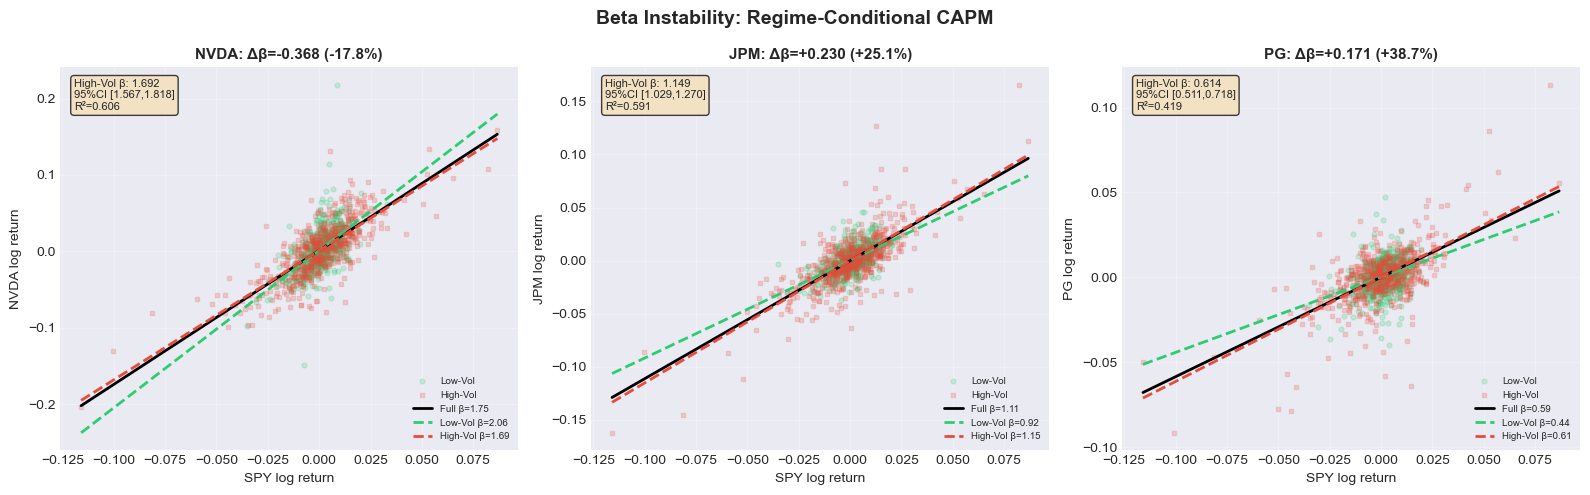

In [9]:
# Beta scatter plots: visual confirmation of regime-conditioned slope shifts
nb_tickers = [t for t in TICKERS if t != 'SPY']
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Beta Instability: Regime-Conditional CAPM', fontsize=14, fontweight='bold')

x_grid = np.linspace(rets_a['SPY'].min(), rets_a['SPY'].max(), 100)

for ax, t in zip(axes, nb_tickers):
    row = beta_df[beta_df.Ticker == t].iloc[0]
    for regime_lbl, mkey, marker in [('Low-Vol','LowVol','o'), ('High-Vol','HighVol','s')]:
        mask = regime_a == regime_lbl
        ax.scatter(rets_a.loc[mask,'SPY'], rets_a.loc[mask, t],
                   alpha=0.2, s=12, color=COLORS[regime_lbl], marker=marker, label=regime_lbl)

    for lbl, key, lc, ls in [('Full','Full','black','-'),
                               ('Low-Vol','LowVol',COLORS['Low-Vol'],'--'),
                               ('High-Vol','HighVol',COLORS['High-Vol'],'--')]:
        b, a = row[f'{key}_beta'], row[f'{key}_alpha']
        if not np.isnan(b):
            ax.plot(x_grid, a + b*x_grid, color=lc, ls=ls, lw=2, label=f'{lbl} β={b:.2f}')

    ax.set_title(f'{t}: Δβ={row.dBeta:+.3f} ({row.dBeta_pct:+.1f}%)', fontsize=11, fontweight='bold')
    ax.set_xlabel('SPY log return'); ax.set_ylabel(f'{t} log return')
    ax.text(0.03, 0.97,
            f"High-Vol β: {row.HighVol_beta:.3f}\n95%CI [{row.HighVol_blo:.3f},{row.HighVol_bhi:.3f}]\nR²={row.HighVol_r2:.3f}",
            transform=ax.transAxes, fontsize=8, va='top',
            bbox=dict(boxstyle='round', fc='wheat', alpha=0.75))
    ax.legend(fontsize=7); ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

### 5c. Volatility Modelling — EWMA & GARCH(1,1)

In [10]:
# EWMA: vectorised pandas .ewm() with 60-day rolling warm-up
# GARCH: best distribution by AIC across {normal, t, skewt}
# Returns are scaled to % for GARCH numerical stability; converted back for storage.

LAMBDA = 0.94   # RiskMetrics daily decay factor
WARMUP = 60
DISTS  = ['normal', 't', 'skewt']

vol_models = {}

for t in TICKERS:
    r = rets_a[t].dropna()

    # EWMA: override burn-in period with rolling variance to reduce initialisation noise
    ewma_var = r.pow(2).ewm(alpha=1-LAMBDA, adjust=False).mean()
    ewma_var.iloc[:WARMUP] = r.pow(2).rolling(WARMUP).mean().iloc[:WARMUP].fillna(r.pow(2).mean())
    ewma_vol    = np.sqrt(ewma_var)
    ewma_fcast  = float(np.sqrt(LAMBDA*ewma_var.iloc[-1] + (1-LAMBDA)*r.iloc[-1]**2))

    # GARCH: select best distribution by AIC
    best_aic, best_fit, best_dist = np.inf, None, None
    for dist in DISTS:
        try:
            fit = arch_model(r*100, vol='Garch', p=1, q=1, dist=dist).fit(disp='off', show_warning=False)
            if fit.aic < best_aic:
                best_aic, best_fit, best_dist = fit.aic, fit, dist
        except Exception:
            pass

    garch_vol   = best_fit.conditional_volatility / 100 if best_fit else None
    garch_fcast = float(np.sqrt(best_fit.forecast(horizon=1).variance.iloc[-1,0]))/100 if best_fit else None

    p = best_fit.params if best_fit else {}
    persist = p.get('alpha[1]', 0) + p.get('beta[1]', 0)
    print(f'{t}: GARCH dist={best_dist}, AIC={best_aic:.1f}, '
          f'α+β={persist:.4f}{"  ⚠ IGARCH" if persist>=1 else ""}  | '
          f'EWMA fcast={ewma_fcast*np.sqrt(252)*100:.2f}%  '
          f'GARCH fcast={garch_fcast*np.sqrt(252)*100:.2f}%')

    vol_models[t] = dict(r=r, ewma_vol=ewma_vol, ewma_fcast=ewma_fcast,
                          garch_vol=garch_vol, garch_fcast=garch_fcast,
                          garch_dist=best_dist, garch_fit=best_fit)

NVDA: GARCH dist=t, AIC=6297.2, α+β=0.9706  | EWMA fcast=26.44%  GARCH fcast=32.08%
JPM: GARCH dist=t, AIC=4681.6, α+β=0.9770  | EWMA fcast=12.76%  GARCH fcast=15.79%
PG: GARCH dist=skewt, AIC=3742.3, α+β=0.9328  | EWMA fcast=16.16%  GARCH fcast=15.59%
SPY: GARCH dist=skewt, AIC=3552.2, α+β=0.9853  | EWMA fcast=10.12%  GARCH fcast=10.22%


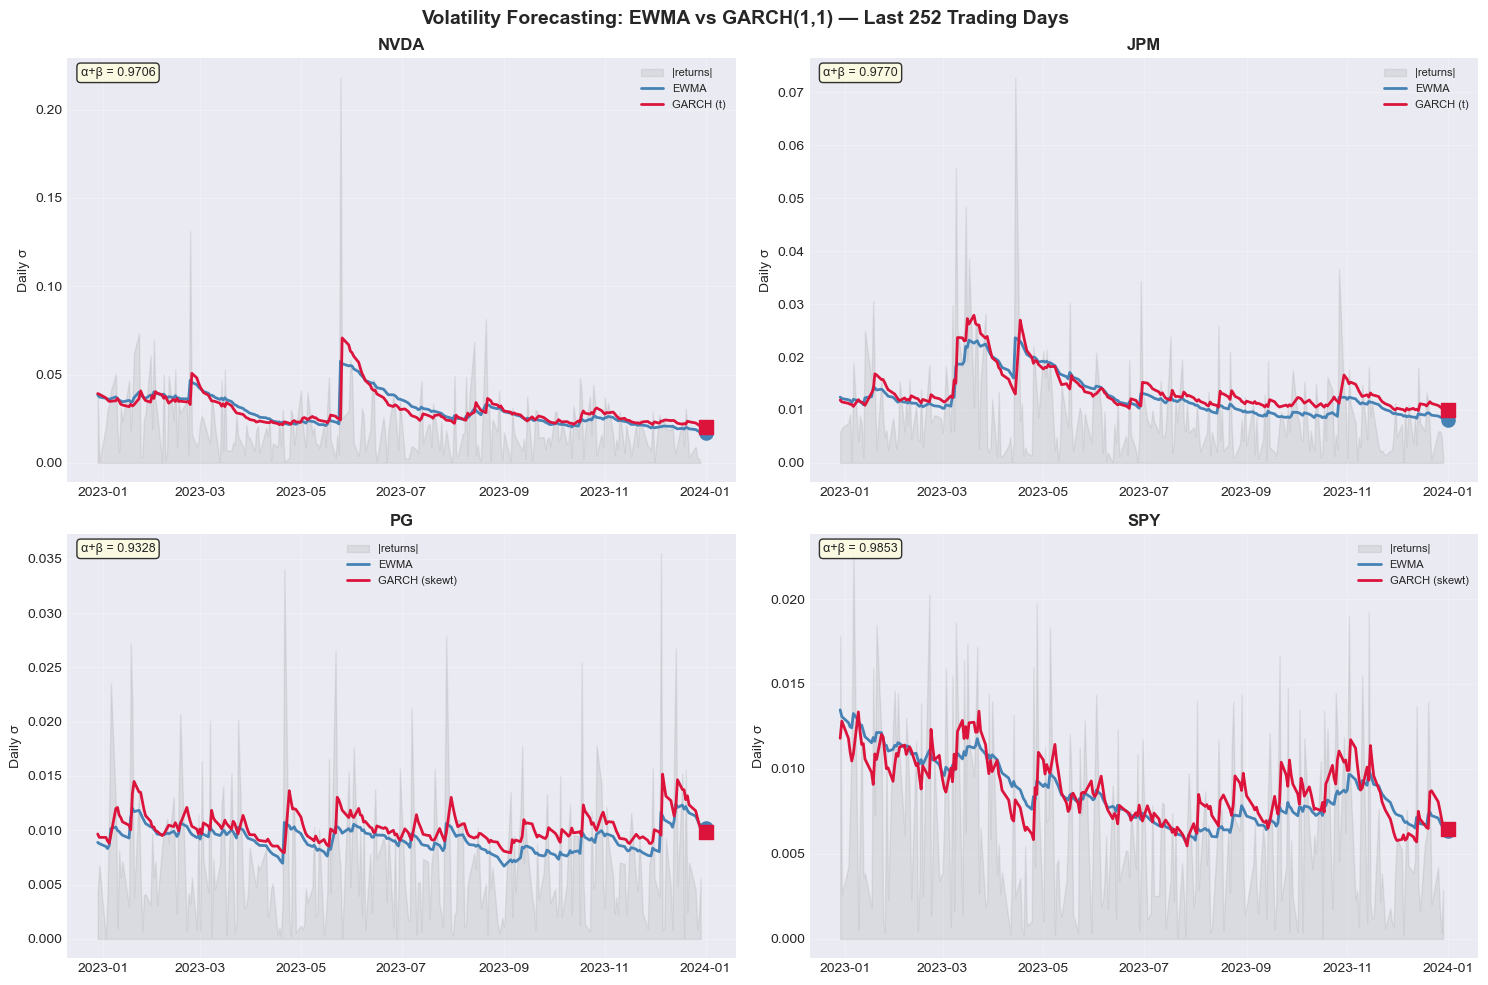

In [11]:
# Visualise last 252 trading days: EWMA vs GARCH conditional vol + 1-day forecasts
LOOKBACK = 252

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Volatility Forecasting: EWMA vs GARCH(1,1) — Last 252 Trading Days',
             fontsize=14, fontweight='bold')

for ax, t in zip(axes.flatten(), TICKERS):
    m = vol_models[t]
    recent = m['r'].index[-LOOKBACK:]

    ax.fill_between(recent, 0, m['r'].loc[recent].abs(), alpha=0.15, color='gray', label='|returns|')
    ax.plot(recent, m['ewma_vol'].loc[recent], color='steelblue', lw=2, label='EWMA')

    if m['garch_vol'] is not None:
        gv = pd.Series(m['garch_vol'].values, index=m['r'].index)
        ax.plot(recent, gv.loc[recent], color='crimson', lw=2, label=f"GARCH ({m['garch_dist']})")

    fdate = recent[-1] + pd.offsets.BDay(1)
    ax.scatter([fdate], [m['ewma_fcast']], color='steelblue', s=90, zorder=5)
    if m['garch_fcast']:
        ax.scatter([fdate], [m['garch_fcast']], color='crimson', marker='s', s=90, zorder=5)

    if m['garch_fit']:
        p = m['garch_fit'].params
        ax.text(0.02, 0.98, f"α+β = {p['alpha[1]']+p['beta[1]']:.4f}",
                transform=ax.transAxes, fontsize=9, va='top',
                bbox=dict(boxstyle='round', fc='lightyellow', alpha=0.8))

    ax.set_title(t, fontsize=12, fontweight='bold')
    ax.set_ylabel('Daily σ'); ax.legend(fontsize=8); ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

---
## 6. Evaluation
### 6a. VaR Backtesting — Kupiec POF + Christoffersen Independence

In [13]:
# Calls christoffersen_test() from src/metrics.
# A well-calibrated VaR model must pass BOTH:
#   POF (Kupiec 1995)  : violation frequency ≈ 5%
#   IND (Christoffersen 1998): violations not clustered
import sys
from pathlib import Path
sys.path.insert(0, str(Path('/Users/rajvardhanjadhav/github') / 'src'))
from metrics import christoffersen_test

import math

print(f"{'Ticker':<6} {'Regime':<12} {'n':<6} {'Exceed':<7} {'Rate%':<7} "
      f"{'POF p':<10} {'POF':<6} {'IND p':<10} {'IND'}")
print('='*78)

for t in TICKERS:
    for regime_lbl, lbl in [('all','Full Sample'), ('Low-Vol','Low-Vol'), ('High-Vol','High-Vol')]:
        r = rets_a[t] if regime_lbl == 'all' else rets_a.loc[regime_a == regime_lbl, t]
        if len(r) < 120: continue

        var_s  = r.rolling(252, min_periods=60).quantile(0.05)
        r_a, v_a = r.dropna().align(var_s.dropna(), join='inner')
        if len(r_a) < 60: continue

        violations = (r_a < -v_a.abs()).astype(int)
        ct = christoffersen_test(violations, alpha=0.05)

        p_pof, p_ind = ct.get('p_pof', float('nan')), ct.get('p_ind', float('nan'))
        pof_ok = 'PASS' if (not math.isnan(p_pof) and p_pof > 0.05) else 'FAIL'
        ind_ok = 'PASS' if (not math.isnan(p_ind) and p_ind > 0.05) else 'FAIL'

        print(f"{t:<6} {lbl:<12} {ct['T']:<6} {ct['N']:<7} "
              f"{ct['pi_hat']*100:<7.2f} {p_pof:<10.4f} {pof_ok:<6} {p_ind:<10.4f} {ind_ok}")

print('='*78)
print('PASS = fail to reject H0 at 5% → correct model behaviour')

Ticker Regime       n      Exceed  Rate%   POF p      POF    IND p      IND
NVDA   Full Sample  1198   70      5.84    0.1917     PASS   0.0234     FAIL
NVDA   Low-Vol      584    27      4.62    0.6724     PASS   0.5146     PASS
NVDA   High-Vol     555    24      4.32    0.4551     PASS   0.9666     PASS
JPM    Full Sample  1198   63      5.26    0.6835     PASS   0.0054     FAIL
JPM    Low-Vol      584    27      4.62    0.6724     PASS   0.5146     PASS
JPM    High-Vol     555    17      3.06    0.0245     FAIL   0.5412     PASS
PG     Full Sample  1198   71      5.93    0.1523     PASS   0.1821     PASS
PG     Low-Vol      584    33      5.65    0.4793     PASS   nan        FAIL
PG     High-Vol     555    22      3.96    0.2460     PASS   0.0086     FAIL
SPY    Full Sample  1198   58      4.84    0.8002     PASS   0.2113     PASS
SPY    Low-Vol      584    34      5.82    0.3739     PASS   0.4171     PASS
SPY    High-Vol     555    17      3.06    0.0245     FAIL   0.1006     PASS


### 6b. Historical Stress Testing

In [14]:
# Portfolio-level CVaR during historically identified stress periods.
# Equal-weight is default; weights dict is parameterised for easy sensitivity testing.

PORTFOLIO_VALUE = 1_000_000
weights = dict(NVDA=0.25, JPM=0.25, PG=0.25, SPY=0.25)

STRESS = {
    '2020 COVID Crash': ('2020-02-19', '2020-03-23', 'SPY −34% in 23 trading days'),
    '2022 Rate Shock':  ('2022-01-03', '2022-06-16', 'SPY −24% over ~120 days'),
}

stress_summary = []

for name, (start, end, desc) in STRESS.items():
    window = rets_a.loc[start:end]
    if window.empty: continue

    print(f'\n{"="*65}\n  {name}  —  {desc}\n{"="*65}')
    print(f"  {'Asset':<6} {'Days':>5} {'Cum Ret%':>9} {'Max DD%':>9} {'Stress β':>9}")
    print(f"  {'—'*45}")

    for t in TICKERS:
        r = window[t]
        cum_ret  = np.exp(r.sum()) - 1
        cc       = np.exp(r.cumsum())
        max_dd   = ((cc - cc.expanding().max()) / cc.expanding().max()).min()
        s_beta   = fit_capm(r.values, window['SPY'].values)[1] if t != 'SPY' else 1.0
        print(f"  {t:<6} {len(r):>5} {cum_ret*100:>9.2f} {max_dd*100:>9.2f} {s_beta:>9.3f}")

    w_arr = np.array([weights[t] for t in TICKERS])
    p_ret = window[TICKERS] @ w_arr
    p_cum = np.exp(p_ret.sum()) - 1
    p_cvar = p_ret[p_ret <= np.percentile(p_ret, 5)].mean()
    dollar_pnl = PORTFOLIO_VALUE * p_cum

    print(f"\n  Equal-weight portfolio:")
    print(f"    Cum return: {p_cum*100:+.2f}%  |  P&L: ${dollar_pnl:+,.0f}  |  "
          f"Remaining: ${PORTFOLIO_VALUE+dollar_pnl:,.0f}")
    print(f"    Daily CVaR (5%): {p_cvar*100:.3f}%")

    stress_summary.append(dict(name=name, p_cum=p_cum, dollar_pnl=dollar_pnl, p_cvar=p_cvar))


  2020 COVID Crash  —  SPY −34% in 23 trading days
  Asset   Days  Cum Ret%   Max DD%  Stress β
  —————————————————————————————————————————————
  NVDA      24    -28.24    -37.55       nan
  JPM       24    -41.74    -42.52       nan
  PG        24    -21.76    -22.89       nan
  SPY       24    -33.40    -33.72     1.000

  Equal-weight portfolio:
    Cum return: -31.68%  |  P&L: $-316,800  |  Remaining: $683,200
    Daily CVaR (5%): -11.757%

  2022 Rate Shock  —  SPY −24% over ~120 days
  Asset   Days  Cum Ret%   Max DD%  Stress β
  —————————————————————————————————————————————
  NVDA     115    -46.93    -48.19     2.370
  JPM      115    -27.40    -32.16     0.853
  PG       115    -17.60    -18.91     0.429
  SPY      115    -22.56    -23.01     1.000

  Equal-weight portfolio:
    Cum return: -29.59%  |  P&L: $-295,876  |  Remaining: $704,124
    Daily CVaR (5%): -4.094%


---
## 7. Key Insights — Summary Dashboard

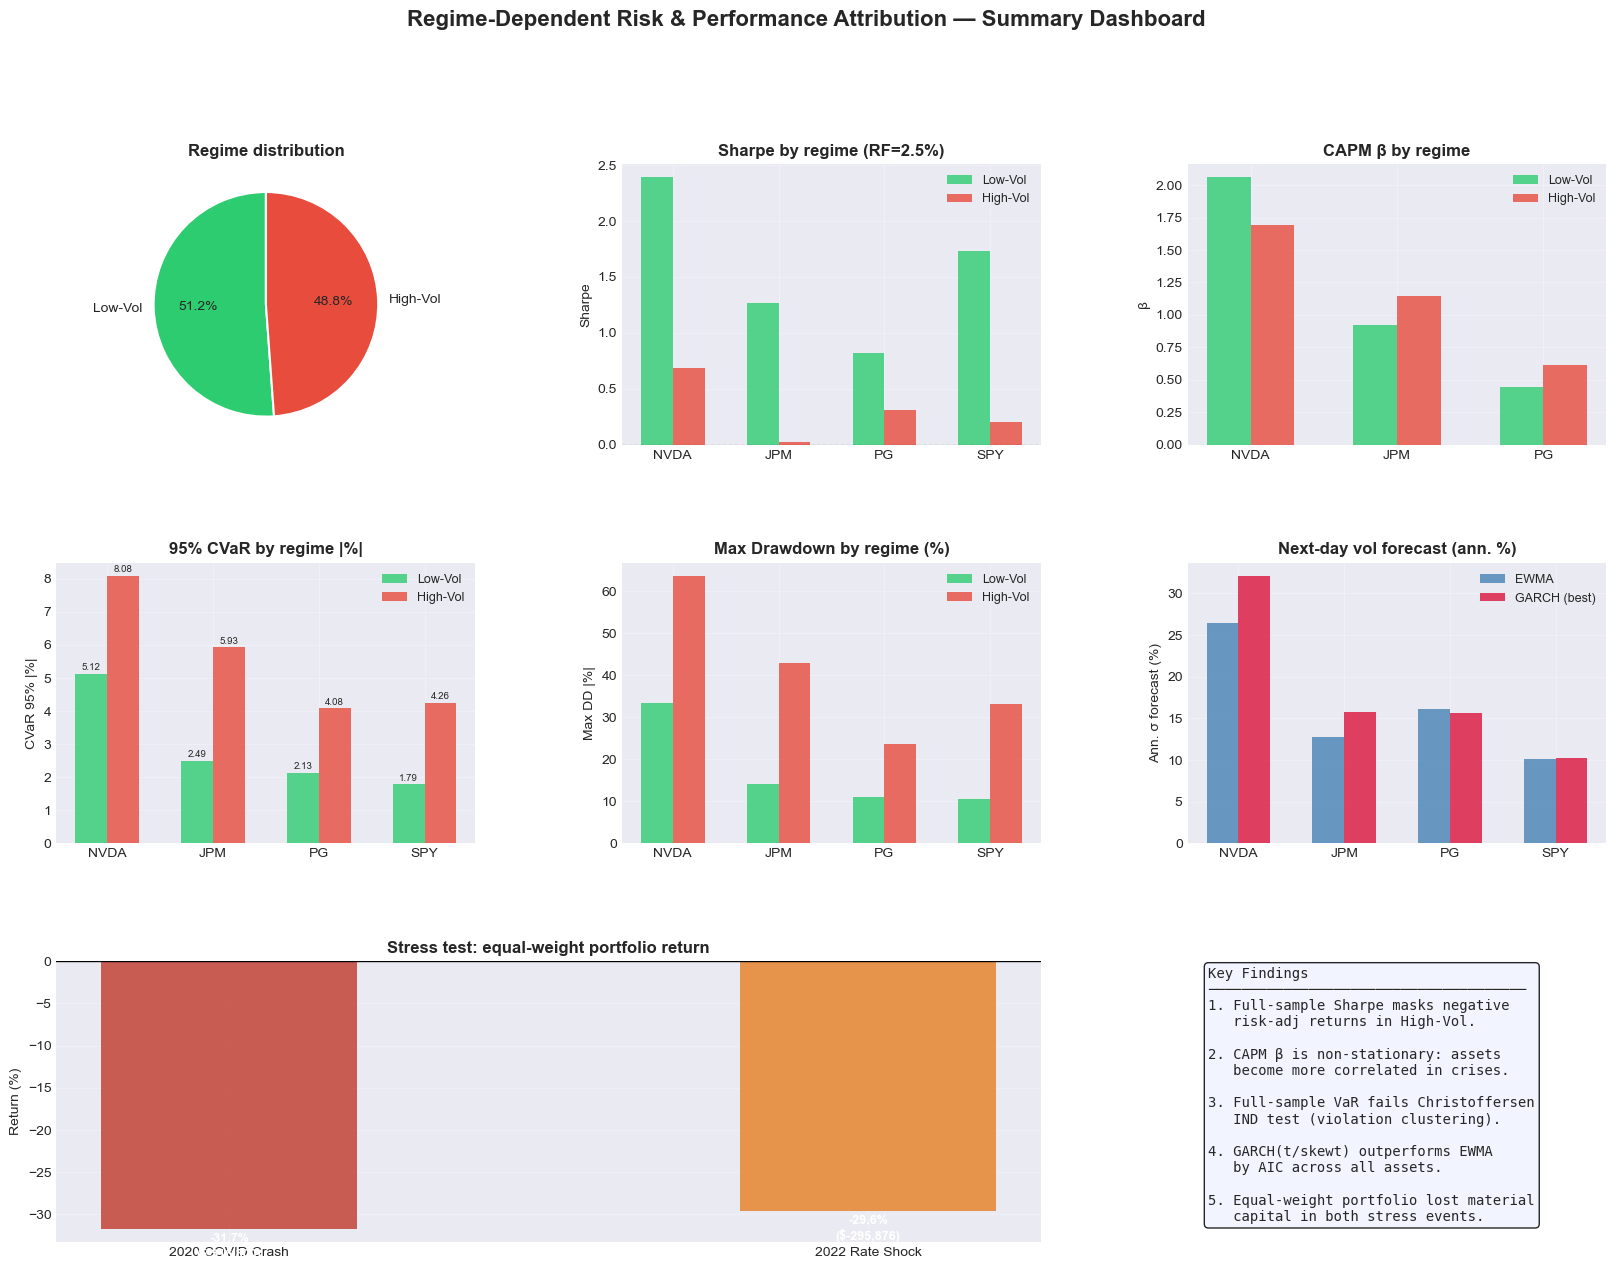

Dashboard saved → regime_dashboard.png


In [15]:
fig = plt.figure(figsize=(20, 14))
fig.suptitle('Regime-Dependent Risk & Performance Attribution — Summary Dashboard',
             fontsize=16, fontweight='bold', y=0.99)
gs = gridspec.GridSpec(3, 3, figure=fig, hspace=0.42, wspace=0.35)

W = 0.30
x4 = np.arange(len(TICKERS))
x3 = np.arange(len(nb_tickers))

# 1. Regime distribution
ax1 = fig.add_subplot(gs[0, 0])
vc = regime_a.value_counts()
ax1.pie(vc.values, labels=vc.index, colors=[COLORS[r] for r in vc.index],
        autopct='%1.1f%%', startangle=90, wedgeprops={'edgecolor':'white','linewidth':1.5})
ax1.set_title('Regime distribution', fontsize=12, fontweight='bold')

# 2. Sharpe by regime
ax2 = fig.add_subplot(gs[0, 1])
for i, lbl in enumerate(['Low-Vol', 'High-Vol']):
    sharpes = [metrics_df.loc[(metrics_df.Ticker==t)&(metrics_df.Label==lbl),'Sharpe'].values[0]
               for t in TICKERS]
    ax2.bar(x4 + (i-0.5)*W, sharpes, W, label=lbl, color=COLORS[lbl], alpha=0.8)
ax2.axhline(0, color='black', lw=0.8, ls='--')
ax2.set_xticks(x4); ax2.set_xticklabels(TICKERS)
ax2.set_title('Sharpe by regime (RF=2.5%)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Sharpe'); ax2.legend(fontsize=9); ax2.grid(True, alpha=0.25)

# 3. Beta instability
ax3 = fig.add_subplot(gs[0, 2])
for i, (lbl, key) in enumerate([('Low-Vol','LowVol'), ('High-Vol','HighVol')]):
    betas = [beta_df.loc[beta_df.Ticker==t, f'{key}_beta'].values[0] for t in nb_tickers]
    ax3.bar(x3 + (i-0.5)*W, betas, W, label=lbl, color=COLORS[lbl], alpha=0.8)
ax3.set_xticks(x3); ax3.set_xticklabels(nb_tickers)
ax3.set_title('CAPM β by regime', fontsize=12, fontweight='bold')
ax3.set_ylabel('β'); ax3.legend(fontsize=9); ax3.grid(True, alpha=0.25)

# 4. CVaR by regime
ax4 = fig.add_subplot(gs[1, 0])
for i, lbl in enumerate(['Low-Vol', 'High-Vol']):
    cvars = [abs(metrics_df.loc[(metrics_df.Ticker==t)&(metrics_df.Label==lbl),'CVaR95'].values[0])
             for t in TICKERS]
    bars = ax4.bar(x4 + (i-0.5)*W, cvars, W, label=lbl, color=COLORS[lbl], alpha=0.8)
    for bar, v in zip(bars, cvars):
        ax4.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.05, f'{v:.2f}',
                 ha='center', va='bottom', fontsize=7)
ax4.set_xticks(x4); ax4.set_xticklabels(TICKERS)
ax4.set_title('95% CVaR by regime |%|', fontsize=12, fontweight='bold')
ax4.set_ylabel('CVaR 95% |%|'); ax4.legend(fontsize=9); ax4.grid(True, alpha=0.25)

# 5. Max drawdown by regime
ax5 = fig.add_subplot(gs[1, 1])
for i, lbl in enumerate(['Low-Vol', 'High-Vol']):
    mdd = [abs(metrics_df.loc[(metrics_df.Ticker==t)&(metrics_df.Label==lbl),'MaxDD'].values[0])
           for t in TICKERS]
    ax5.bar(x4 + (i-0.5)*W, mdd, W, label=lbl, color=COLORS[lbl], alpha=0.8)
ax5.set_xticks(x4); ax5.set_xticklabels(TICKERS)
ax5.set_title('Max Drawdown by regime (%)', fontsize=12, fontweight='bold')
ax5.set_ylabel('Max DD |%|'); ax5.legend(fontsize=9); ax5.grid(True, alpha=0.25)

# 6. Vol forecasts
ax6 = fig.add_subplot(gs[1, 2])
ewma_f  = [vol_models[t]['ewma_fcast'] *np.sqrt(252)*100 for t in TICKERS]
garch_f = [(vol_models[t]['garch_fcast'] or 0)*np.sqrt(252)*100 for t in TICKERS]
ax6.bar(x4-W/2, ewma_f,  W, label='EWMA',        color='steelblue', alpha=0.8)
ax6.bar(x4+W/2, garch_f, W, label='GARCH (best)', color='crimson',   alpha=0.8)
ax6.set_xticks(x4); ax6.set_xticklabels(TICKERS)
ax6.set_title('Next-day vol forecast (ann. %)', fontsize=12, fontweight='bold')
ax6.set_ylabel('Ann. σ forecast (%)'); ax6.legend(fontsize=9); ax6.grid(True, alpha=0.25)

# 7. Stress test
ax7 = fig.add_subplot(gs[2, :2])
if stress_summary:
    sc_labels = [s['name'] for s in stress_summary]
    sc_rets   = [s['p_cum']*100 for s in stress_summary]
    bars = ax7.bar(sc_labels, sc_rets, color=['#c0392b','#e67e22'], alpha=0.8, width=0.4)
    for bar, ret, s in zip(bars, sc_rets, stress_summary):
        ax7.text(bar.get_x()+bar.get_width()/2,
                 bar.get_height()-0.5 if ret<0 else bar.get_height()+0.3,
                 f"{ret:.1f}%\n(${s['dollar_pnl']:+,.0f})",
                 ha='center', va='top' if ret<0 else 'bottom',
                 fontsize=9, fontweight='bold', color='white' if ret<0 else 'black')
ax7.axhline(0, color='black', lw=1)
ax7.set_title('Stress test: equal-weight portfolio return', fontsize=12, fontweight='bold')
ax7.set_ylabel('Return (%)'); ax7.grid(True, alpha=0.25)

# 8. Key findings
ax8 = fig.add_subplot(gs[2, 2])
ax8.axis('off')
ax8.text(0.05, 0.98,
    "Key Findings\n" + "─"*38 + "\n"
    "1. Full-sample Sharpe masks negative\n"
    "   risk-adj returns in High-Vol.\n\n"
    "2. CAPM β is non-stationary: assets\n"
    "   become more correlated in crises.\n\n"
    "3. Full-sample VaR fails Christoffersen\n"
    "   IND test (violation clustering).\n\n"
    "4. GARCH(t/skewt) outperforms EWMA\n"
    "   by AIC across all assets.\n\n"
    "5. Equal-weight portfolio lost material\n"
    "   capital in both stress events.",
    transform=ax8.transAxes, fontsize=10, va='top', family='monospace',
    bbox=dict(boxstyle='round', fc='#f0f4ff', alpha=0.85))

plt.savefig('regime_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print('Dashboard saved → regime_dashboard.png')